<a href="https://colab.research.google.com/github/IAMIOT1/h-c-m-y-/blob/main/h%E1%BB%8Dc_kh%C3%B4ng_gi%C3%A1m_s%C3%A1t.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHẦN 1: TẢI DỮ LIỆU & TỔNG HỢP VECTOR ĐẶC TRƯNG

In [9]:
import pandas as pd
import numpy as np
import os

# ==========================================
# 0. KẾT NỐI VỚI GOOGLE DRIVE TRÊN COLAB
# ==========================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Định nghĩa đường dẫn Drive
folder_path = '/content/drive/MyDrive/kiemtrahocmay/'

# ==========================================
# 1. LOAD DỮ LIỆU GỐC (DÙNG FILE 1, 3, 6)
# ==========================================
# File 1: Thông tin khách hàng (Thêm low_memory=False để tránh cảnh báo kiểu dữ liệu)
customer = pd.read_csv(os.path.join(folder_path, "1.Data_Customer.csv"), low_memory=False)
customer.columns = customer.columns.str.strip().str.upper()

# ĐIỀU CHỈNH TÊN FILE SỐ 3 VÀ SỐ 6 CHO KHỚP VỚI THỰC TẾ TRONG DRIVE CỦA BẠN:
# Nếu file số 3 của bạn là file giao dịch, hãy sửa lại tên chuỗi bên dưới cho đúng 100%
file_3_name = "2.Data_MyVIB_Transaction.csv"  # Hoặc tên file 3 thực tế của bạn
file_6_name = "5.Data_Lending.xlsx"           # Hoặc tên file 6 thực tế của bạn

file_3_path = os.path.join(folder_path, file_3_name)
file_6_path = os.path.join(folder_path, file_6_name)

# Đọc file 3 và file 6 dựa theo định dạng đuôi file (.csv hoặc .xlsx)
if file_3_name.endswith(('.xlsx', '.xls')):
    df_3 = pd.read_excel(file_3_path)
else:
    df_3 = pd.read_csv(file_3_path, low_memory=False)

if file_6_name.endswith(('.xlsx', '.xls')):
    df_6 = pd.read_excel(file_6_path)
else:
    df_6 = pd.read_csv(file_6_path, low_memory=False)

df_3.columns = df_3.columns.str.strip().str.upper()
df_6.columns = df_6.columns.str.strip().str.upper()

# ==========================================
# 2. TỔNG HỢP VECTOR ĐẶC TRƯNG TÀI CHÍNH
# ==========================================
# Tổng hợp từ File 3 (Dữ liệu giao dịch)
agg_3 = df_3.groupby("CUSTOMER_NUMBER").agg(
    F3_SUM=("TRANS_AMOUNT", "sum"),
    F3_MEAN=("TRANS_AMOUNT", "mean"),
    F3_COUNT=("TRANS_AMOUNT", "count")
).reset_index()

# Tổng hợp từ File 6 (Dữ liệu khoản vay)
agg_6 = df_6.groupby("CUSTOMER_NUMBER").agg(
    F6_MEAN=("AVG_LOAN_AMOUNT", "mean")
).reset_index()

# Merge về bảng customer chung
df_cluster = customer[["CUSTOMER_NUMBER"]].copy()
df_cluster = df_cluster.merge(agg_3, on="CUSTOMER_NUMBER", how="left")
df_cluster = df_cluster.merge(agg_6, on="CUSTOMER_NUMBER", how="left")
df_cluster.fillna(0, inplace=True)

print("Đã tổng hợp dữ liệu thành công! Shape:", df_cluster.shape)
print(df_cluster.head())

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


Đã tổng hợp dữ liệu thành công! Shape: (290223, 5)
   CUSTOMER_NUMBER      F3_SUM       F3_MEAN  F3_COUNT      F6_MEAN
0           639362  21231000.0  1.633154e+06      13.0          0.0
1           452440         0.0  0.000000e+00       0.0          0.0
2           326290  86799392.0  1.846796e+06      47.0          0.0
3            20802         0.0  0.000000e+00       0.0          0.0
4           114244         0.0  0.000000e+00       0.0  295312500.0


PHẦN 2: CHUẨN HÓA DỮ LIỆU (FEATURE SCALING)

In [10]:
from sklearn.preprocessing import StandardScaler

# Chọn các cột đặc trưng tài chính từ File 3 và File 6
feature_cols = ["F3_SUM", "F3_MEAN", "F3_COUNT", "F6_MEAN"]

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[feature_cols])

print("Chuẩn hóa dữ liệu thành công! Kích thước mảng X_scaled:", X_scaled.shape)

Chuẩn hóa dữ liệu thành công! Kích thước mảng X_scaled: (290223, 4)


PHẦN 3: PHƯƠNG PHÁP ELBOW VỚI K-MEANS++ (TÌM SỐ CỤM TỐI ƯU)

K = 1 | Inertia = 1160892.00
K = 2 | Inertia = 905610.81
K = 3 | Inertia = 744745.62
K = 4 | Inertia = 604672.37
K = 5 | Inertia = 460905.76
K = 6 | Inertia = 411052.93
K = 7 | Inertia = 362767.27
K = 8 | Inertia = 323589.19


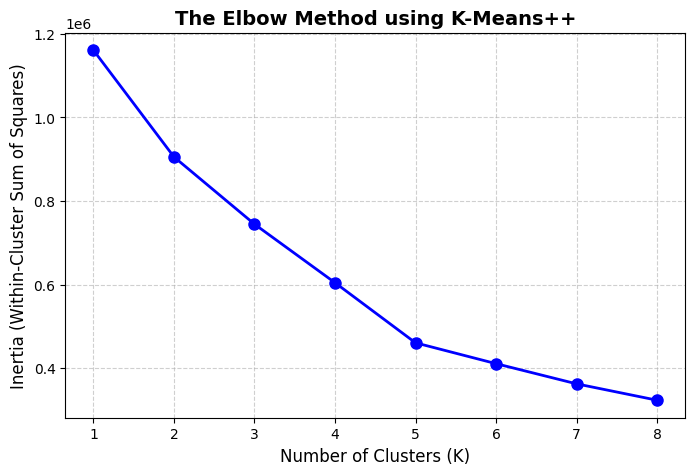

In [11]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia_values = []
K_range = range(1, 9)

for k in K_range:
    # Sử dụng init='k-means++' tối ưu khởi tạo tâm cụm
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)
    print(f"K = {k} | Inertia = {kmeans.inertia_:.2f}")

# Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('The Elbow Method using K-Means++', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(K_range)
plt.show()

PHẦN 4: HUẤN LUYỆN K-MEANS++ CHÍNH THỨC & XUẤT KẾT QUẢ

In [12]:
# Chọn số cụm tối ưu (dựa trên biểu đồ Elbow ở Phần 3, thường chọn K = 3)
optimal_k = 3
print(f"=> Tiến hành phân cụm chính thức với số cụm: K = {optimal_k}")

kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df_cluster["CLUSTER"] = kmeans_final.fit_predict(X_scaled)

# Tính giá trị trung bình các đặc trưng theo từng cụm
cluster_profile = df_cluster.groupby("CLUSTER")[feature_cols].mean().reset_index()
print("\n--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG CỤM ---")
print(cluster_profile)

# Lưu file kết quả phân cụm ra Google Drive
output_file = os.path.join(folder_path, "customer_clusters_file1_3_6.csv")
df_cluster.to_csv(output_file, index=False)
print(f"\nSaved thành công file tại: {output_file}")

=> Tiến hành phân cụm chính thức với số cụm: K = 3

--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG CỤM ---
   CLUSTER        F3_SUM       F3_MEAN    F3_COUNT       F6_MEAN
0        0  2.209548e+07  1.207724e+06    4.423618  1.576193e+08
1        1  5.274311e+09  1.923354e+08  121.435048  3.932458e+08
2        2  0.000000e+00  0.000000e+00    0.000000  1.638633e+11

Saved thành công file tại: /content/drive/MyDrive/kiemtrahocmay/customer_clusters_file1_3_6.csv
